# Historical Mean Profile — Baseline

Este notebook implementa y evalua el baseline mas simple del pipeline:
para cada combinacion de `mes + dia_semana + es_feriado`, predice el perfil
promedio historico de train. No hay parametros, no hay aprendizaje.

Este modelo establece el piso minimo. Cualquier modelo posterior que no lo
supere en MAE tiene un problema.

In [13]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [14]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt

project_root = Path.cwd().parent
sys.path.append(str(project_root / 'src'))

from historical_mean import (
    fit, predict, evaluate, evaluation_summary,
    extract_province, PROVINCE_ORDER,
)

SPLITS_DIR    = project_root / 'data' / 'splits'
PROCESSED_DIR = project_root / 'data' / 'processed'
RESULTS_DIR   = project_root / 'results'
RESULTS_DIR.mkdir(exist_ok=True)

## 1. Cargar datos

Cargamos los arrays del split y el scaler. Para el calendario usamos
`c_calendario.csv` directamente — necesitamos los valores originales sin escalar
para agrupar por mes, dia_semana y es_feriado.

In [15]:
# Arrays del split
X_train = np.load(SPLITS_DIR / 'X_train.npy')
X_val   = np.load(SPLITS_DIR / 'X_val.npy')
X_test  = np.load(SPLITS_DIR / 'X_test.npy')

dates_train = np.load(SPLITS_DIR / 'dates_train.npy', allow_pickle=True)
dates_val   = np.load(SPLITS_DIR / 'dates_val.npy',   allow_pickle=True)
dates_test  = np.load(SPLITS_DIR / 'dates_test.npy',  allow_pickle=True)

# Scaler para inverse transform
with open(SPLITS_DIR / 'x_scaler.pkl', 'rb') as f:
    x_scaler = pickle.load(f)

# Calendario original sin escalar
c_calendar = pd.read_csv(PROCESSED_DIR / 'c_calendario.csv', parse_dates=['fecha'])

print(f'X_train: {X_train.shape}')
print(f'X_val:   {X_val.shape}')
print(f'X_test:  {X_test.shape}')
print(f'Calendario: {c_calendar.shape}')

X_train: (1457, 528)
X_val:   (366, 528)
X_test:  (485, 528)
Calendario: (2311, 4)


## 2. Entrenar el modelo

Calculamos el perfil promedio para cada grupo de calendario.
Solo usamos datos de train.

In [17]:
model = fit(X_train, dates_train, c_calendar)

print(f'Grupos nivel 3 (mes+dia+feriado): {len(model["level3"])}')
print(f'Grupos nivel 2 (mes+dia):         {len(model["level2"])}')
print(f'Grupos nivel 1 (mes):             {len(model["level1"])}')
print(f'Grupos posibles nivel 3:          {12 * 7 * 2}')
print(f'Min dias por grupo:               {model["min_days"]}')

counts3 = pd.Series(model["counts3"])
print(f'\nDias por grupo nivel 3 — min: {counts3.min()}, max: {counts3.max()}, media: {counts3.mean():.1f}')

Grupos nivel 3 (mes+dia+feriado): 93
Grupos nivel 2 (mes+dia):         84
Grupos nivel 1 (mes):             12
Grupos posibles nivel 3:          168
Min dias por grupo:               3

Dias por grupo nivel 3 — min: 3, max: 19, media: 15.3


## 3. Prediccion sobre validacion

Predecimos los perfiles para cada dia de val y evaluamos el error.

In [18]:
X_val_pred, fallback_val = predict(dates_val, c_calendar, model)
print(f"Dias con fallback: {len(fallback_val)}")
print(fallback_val["level_used"].value_counts())

metrics_val = evaluate(X_val, X_val_pred, dates_val, x_scaler)

print(f'Resultados en validacion ({metrics_val["n_days"]} dias):')
print(f'  MAE global:    {metrics_val["mae_global"]:.1f} MWh')
print(f'  RMSE global:   {metrics_val["rmse_global"]:.1f} MWh')
print(f'  MAPE energia:  {metrics_val["mape_energy"]:.2f}%')

Dias con fallback: 11
level_used
level2    11
Name: count, dtype: int64
Resultados en validacion (366 dias):
  MAE global:    77.2 MWh
  RMSE global:   226.5 MWh
  MAPE energia:  7.60%


In [19]:
summary_val = evaluation_summary(metrics_val)
print('MAE por provincia (ordenado de mayor a menor):')
summary_val

MAE por provincia (ordenado de mayor a menor):


,provincia,mae_mwh,rmse_mwh,mape_pct
0,buenos_aires,757.8,998.0,9.25
1,santa_fe,149.4,202.6,9.76
2,cordoba,117.8,169.8,8.64
3,chubut,92.5,121.2,13.92
4,chaco,68.2,97.8,14.57
5,tucuman,55.9,76.2,12.19
6,corrientes,49.5,69.9,11.89
7,misiones,48.2,61.1,13.80
8,mendoza,46.5,65.3,6.15
9,sgo_del_estero,45.2,65.4,16.13


## 4. Visualizaciones

Comparamos el perfil predicho vs el real para algunos dias representativos.

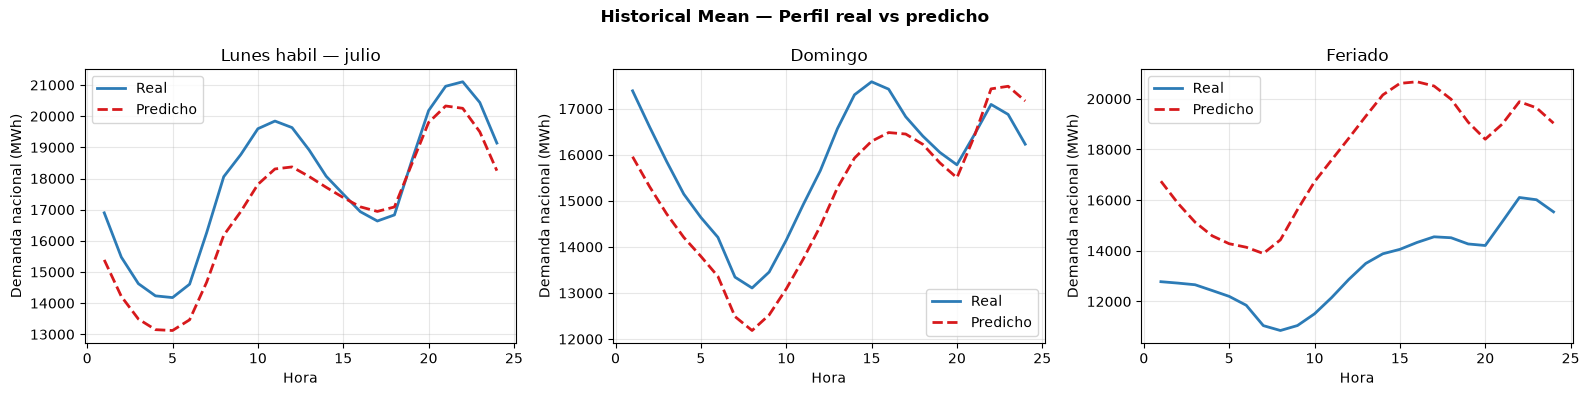

In [20]:
# Seleccionar 3 dias: habil tipico, fin de semana, feriado
dates_val_ts = pd.to_datetime(dates_val)
cal_val = pd.DataFrame({'fecha': dates_val_ts}).merge(
    c_calendar[['fecha', 'mes', 'dia_semana', 'es_feriado']], on='fecha', how='left'
)

# Un lunes habil de invierno
idx_habil = cal_val[
    (cal_val['dia_semana'] == 0) &
    (cal_val['es_feriado'] == 0) &
    (cal_val['mes'] == 7)
].index[0]

# Un domingo
idx_domingo = cal_val[cal_val['dia_semana'] == 6].index[0]

# Un feriado
idx_feriado = cal_val[cal_val['es_feriado'] == 1].index[0] if cal_val['es_feriado'].any() else idx_habil

X_val_mwh      = x_scaler.inverse_transform(X_val)
X_val_pred_mwh = x_scaler.inverse_transform(X_val_pred)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
titulos = ['Lunes habil — julio', 'Domingo', 'Feriado']
indices = [idx_habil, idx_domingo, idx_feriado]

for ax, idx, titulo in zip(axes, indices, titulos):
    # Demanda nacional total (suma de provincias por hora)
    real_nacional = X_val_mwh[idx].reshape(22, 24).sum(axis=0)
    pred_nacional = X_val_pred_mwh[idx].reshape(22, 24).sum(axis=0)
    horas = range(1, 25)
    ax.plot(horas, real_nacional, label='Real', color='#2c7bb6', linewidth=2)
    ax.plot(horas, pred_nacional, label='Predicho', color='#d7191c', linewidth=2, linestyle='--')
    ax.set_title(titulo)
    ax.set_xlabel('Hora')
    ax.set_ylabel('Demanda nacional (MWh)')
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle('Historical Mean — Perfil real vs predicho', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'historical_mean_perfiles.png', dpi=150, bbox_inches='tight')
plt.show()

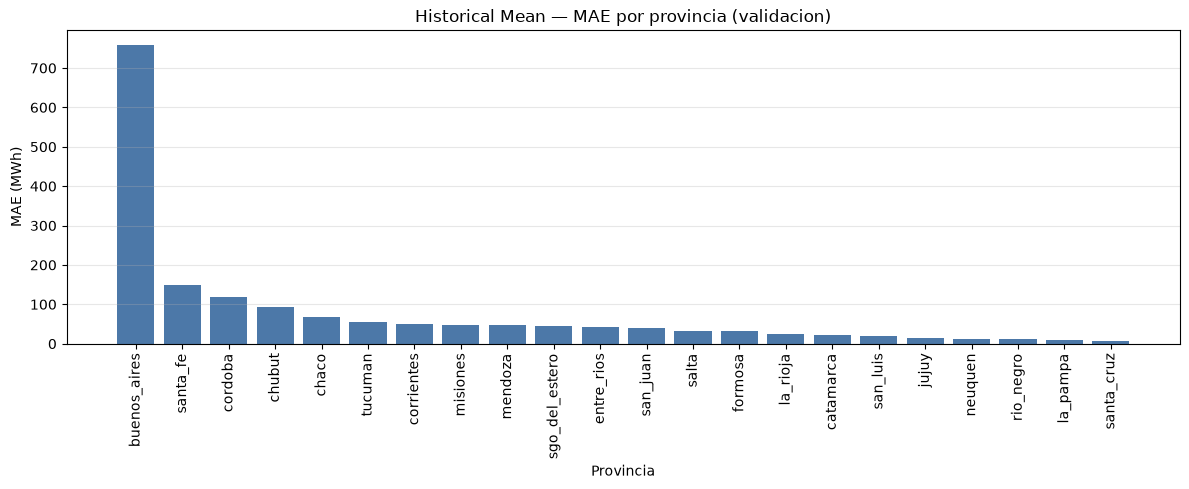

In [21]:
# MAE por provincia — barplot
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(summary_val['provincia'], summary_val['mae_mwh'], color='#4c78a8')
ax.set_title('Historical Mean — MAE por provincia (validacion)')
ax.set_xlabel('Provincia')
ax.set_ylabel('MAE (MWh)')
ax.tick_params(axis='x', rotation=90)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'historical_mean_mae_provincia.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Resultado final en test

Reportamos las metricas sobre test una unica vez al final.
Este numero es el piso que todos los modelos posteriores deben superar.

In [22]:
X_test_pred, fallback_test = predict(dates_test, c_calendar, model)
print(f"Dias con fallback: {len(fallback_test)}")
print(fallback_test["level_used"].value_counts())

metrics_test = evaluate(X_test, X_test_pred, dates_test, x_scaler)

print('=== RESULTADO FINAL EN TEST ===')
print(f'  MAE global:    {metrics_test["mae_global"]:.1f} MWh')
print(f'  RMSE global:   {metrics_test["rmse_global"]:.1f} MWh')
print(f'  MAPE energia:  {metrics_test["mape_energy"]:.2f}%')
print()
summary_test = evaluation_summary(metrics_test)
summary_test

Dias con fallback: 15
level_used
level2    15
Name: count, dtype: int64
=== RESULTADO FINAL EN TEST ===
  MAE global:    76.6 MWh
  RMSE global:   226.2 MWh
  MAPE energia:  7.30%



,provincia,mae_mwh,rmse_mwh,mape_pct
0,buenos_aires,725.5,992.8,8.33
1,santa_fe,158.1,214.6,9.61
2,cordoba,120.8,181.6,8.38
3,chubut,75.0,93.0,12.20
4,chaco,71.7,103.2,14.06
5,corrientes,54.9,78.3,12.10
6,tucuman,52.7,78.7,11.03
7,mendoza,51.6,68.0,7.16
8,sgo_del_estero,49.0,71.9,16.16
9,entre_rios,47.5,72.7,8.44


In [23]:
# Guardar metricas
import json

results = {
    'model': 'historical_mean',
    'val': {
        'mae_global':  round(metrics_val['mae_global'], 2),
        'rmse_global': round(metrics_val['rmse_global'], 2),
        'mape_energy': round(metrics_val['mape_energy'], 4),
    },
    'test': {
        'mae_global':  round(metrics_test['mae_global'], 2),
        'rmse_global': round(metrics_test['rmse_global'], 2),
        'mape_energy': round(metrics_test['mape_energy'], 4),
    },
}

with open(RESULTS_DIR / 'historical_mean_metrics.json', 'w') as f:
    json.dump(results, f, indent=2)

print('Metricas guardadas en results/historical_mean_metrics.json')

Metricas guardadas en results/historical_mean_metrics.json


## 6. Interpretacion de resultados

El baseline historico predice el perfil promedio de demanda segun el grupo de calendario
al que pertenece cada dia. No usa ninguna variable climatica ni informacion del estado
del sistema — solo el mes, el dia de la semana y si es feriado.

**Resultados en test:**

- MAE global de 77 MWh por celda del vector de 528 dimensiones. En contexto, la demanda
  nacional hora a hora oscila entre 10.000 y 25.000 MWh, por lo que este error representa
  aproximadamente un 0.4-0.7% del nivel de demanda de una provincia grande como Buenos Aires
  y un porcentaje mucho mayor para provincias pequeñas como Santa Cruz o La Rioja.

- MAPE de energia diaria de 7.3%. Significa que la energia diaria total predicha
  se aleja en promedio un 7.3% de la real. Para un modelo que ignora completamente
  el clima, este numero es esperable: en dias de temperatura normal el error es bajo,
  pero en olas de calor o frio extremo el promedio historico subestima o sobreestima
  fuertemente la demanda.

- RMSE de 226 MWh, considerablemente mayor que el MAE. La diferencia indica que hay
  dias con errores muy grandes que elevan la raiz cuadratica. Estos son precisamente
  los dias extremos que el calendario no puede anticipar: eventos climaticos, feriados
  atipicos o cambios estructurales en el consumo entre anos.

**Limitaciones del baseline:**

El modelo asume que dos dias del mismo tipo de calendario tienen el mismo perfil de demanda.
Esa suposicion es correcta en promedio pero falla en los extremos. Un lunes de enero habil
con 42 grados tiene una forma y nivel de demanda completamente distinta a un lunes de enero
habil con 20 grados. El baseline no puede distinguir entre esos casos.

Ademas, el fallback jerarquico fue necesario para 50 grupos de feriados que no tenian
suficientes dias en train. Esto refleja que los feriados son eventos raros y heterogeneos
que el promedio historico no puede capturar bien.

**Rol en el pipeline:**

Estos numeros establecen el piso de comparacion. Cualquier modelo posterior que no mejore
el MAE global y el MAPE de energia sobre este baseline no esta aportando valor respecto
a una regla deterministica simple. El CVAE deberia mejorar especialmente en los dias
extremos donde el calendario es insuficiente para explicar el consumo.